# Topic 6 - Basic Text Processing

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Understand text processing fundamentals
2. Apply text processing techniques
3. Manipulate unstructured data

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 6.0 Introduction </h2>
</div>

### 6.0.1 Sources of Unstructured Data
- Documents
- Emails
- Social media
- Customer feedback
- Web pages
- Open-ended survey responses
- Audio and video

### 6.0.2 Challenges in Processing Text Data

Polysemy -- **One word** maps to **many concepts**, e.g., bat
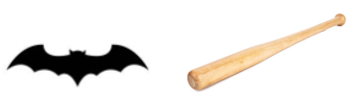 
*<small>(Image Source: Getty Images)</small>*

Synonymy -- **One concept** maps to **many words**, e.g., smart / bright / clever

---

Word **order**
- "Venetian blind" vs. "blind Venetian"
- "Man bites dog" vs. "dog bites man"

---

Language is **generative**
- "Starbucks coffee is my favourite"
- "The place I like most to feed my caffeine addiction is the company from Seattle with branches everywhere"

Many **different ways** to express a given idea, e.g., paraphrase, metaphor, idioms, etc.

--- 

Others
- Language is changing -- "I want to buy a mobile"
- Ill-formed input -- "accomodation office" (spelling error)
- Co-ordination, negation, etc. -- "This is not a talk about neuro-linguistic programming"
- Sarcasm, irony, slang, jargon, etc. -- "That was a wicked lecture", "Yep - the coffee break was the best part"

### 6.0.3 Text Processing Fundamentals

Much of the world's data is **unstructured**, often in the form of **text**. 

Processing text data presents a number of **challenges**. 

However, as humans, we do it effortlessly...
- Drunk gets nine years in violin case
- Stolen painting found by tree
- Red tape holds up new bridge
- Include children when baking cookies
- Miners refuse to work after death

---

Language is **AMBIGUOUS**
- To determine structure, we must **resolve** ambiguity!
- Ambiguity occurs at many **levels**, from **word** level to **sentence** level (and **beyond**)

---

**Lexical analysis** (tokenisation)
- "The cat sat on the mat" -- should be ok
- "I can't tokenise this sentence" -- why problematic?

**Stop word** removal -- no definitive list
- "To be or not to be"

**Stemming**
- fishing, fished, fish, fisher -> fish
- argue, argued, argues, arguing -> argu

**Lemmatization** -- Linguistically principled analysis
- Passing -> pass + ING
- Were -> be + PAST
- Delegate = de-leg-ate (?)
- Ratify = rat-ify (?)

**Morphology** (prefixes, suffixes, etc.)
- 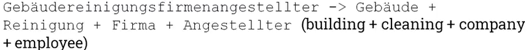


**Syntax** (part of speech tagging)
- noun, pronoun, adjective, determiner, verb, adverb, preposition, conjunction, and interjection
- book -> NOUN, VERB
- that -> DET
- flight -> NOUN
- Book that flight -> VERB DET NOUN

> `Additional Notes`
> * Parts-of-Speech Reference - https://www.butte.edu/departments/cas/tipsheets/grammar/parts_of_speech.html
> * What is a determiner (DET)? It tells us more about a noun, e.g., shows which one, how many, or whose.
> * "Book that flight" more likely VERT DET NOUN rather than NOUN DET NOUN


**Ambiguity** problem:
- Time files like an arrow -> NOUN VERB PREP DET NOUN
- Fruit flies like a banana -> ?
- Eats shoots and leaves -> ?

**Parsing** (grammar)
- I saw a venetian blind
- I saw a blind venitian
- I saw the man on the hill with a telescope

**Sentence boundary detection**
- Punctuation denotes the end of a sentence! "But not always!", said Fred...


<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 6.1 Basic Text Processing (Part 1) </h2>
</div>

### 6.1.1 Sentence Segmentation

Using nltk -- http://www.nltk.org/ 
- An open source platform for working with text data
- Provides acccess to many lexical resources and libraries for all sorts of NLP tasks

In [ ]:
import nltk

In [ ]:
# punkt is a pre-trained sentence tokenizer for English
nltk.download('punkt')

In [ ]:
text = '''Punctuation denotes the end of a sentence!
"But not always!", said Fred... (who is a professor).
Some sentences could break over multiple lines
and begin with a lower case letter.
a1 could be a variable name.
'''
text

In [ ]:
sents = nltk.sent_tokenize(text)

In [ ]:
sents[1]

In [ ]:
len(sents)

In [ ]:
for s in sents:
    print(s)

In [ ]:
print('\n---\n'.join(sents))

In [ ]:
# Try a variation of the original text

text = '''Punctuation denotes the end of a sentence!
"But not always!", said Fred...
some sentences could break over multiple lines
and begin with a lower case letter.
a1 could be a variable name.
'''

sents = nltk.sent_tokenize(text)
print('\n---\n'.join(sents))

### 6.1.2 Word Tokenization

Using nltk http://www.nltk.org/
- Subdividing a character string into component words (tokens)
- Can't we just use whitespace? Beware of compounds, punctuation, contractions, possessives...

In [ ]:
import nltk

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
sents = nltk.sent_tokenize(text)
print('\n---\n'.join(sents))

In [ ]:
[nltk.word_tokenize(s) for s in sents]

In [ ]:
# Try another example

text = '''Most of the time we can use white space.
But what about http://www.nltk.org/, Hewlett-Packard or I.B.M.?
Prof. Russell-Rose thinks that the students' attempts to use nltk's tokenizer aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
sents = nltk.sent_tokenize(text)
print('\n---\n'.join(sents))

In [ ]:
[nltk.word_tokenize(s) for s in sents]

### 6.1.3 Text Normalization

- To relate variations of words to a common form/root, e.g.,
    * run, runs, running -> run
    * am, are, is -> be
- Includes both **stemming** and **lemmatization**
- Need to consider both inflectional forms and derivational forms


In [ ]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import wordnet    
nltk.download('wordnet')

# Note: 
# nltk.download('wordnet') allows you to interact with WordNet,
# a large lexical database of English.

In [ ]:
stemmer = PorterStemmer()
wnl = WordNetLemmatizer()

In [ ]:
word = 'meeting'
stemmer.stem(word), wnl.lemmatize(word)

In [ ]:
# Let's apply stemming and lemmatization to this list of words
words = ['dogs', 'churches', 'aardwolves', 'abaci']  # includes plural form of words

In [ ]:
[stemmer.stem(word) for word in words]

In [ ]:
[wnl.lemmatize(word) for word in words]

In [ ]:
# Let's apply stemming and lemmatization to another list of words
words = ['I', 'am', 'going', 'to', 'a', 'meeting', 'about', 'data', 'science']

In [ ]:
[stemmer.stem(word) for word in words]

In [ ]:
[wnl.lemmatize(word) for word in words]

In [ ]:
[wnl.lemmatize(word, pos='v') for word in words]  # lemmatize as a verb

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 6.2 Basic Text Processing (Part 2) </h2>
</div>

### 6.2.1 Regular Expressions

- A formal language for defining text strings (character sequences)
- Use for pattern matching (e.g., searching & replacing in text)

1. Disjunctions
2. Negation
3. Optionality
4. Aliases
5. Anchors


#### *1. Disjunctions*


In [ ]:
import re

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
# let's try a basic pattern - replace "the" with "X"
pattern = r"the"
print(re.sub(pattern, "X", text))

In [ ]:
### What does this code do?

pattern = r"[Tt]he"
print(re.sub(pattern, "X", text))

In [ ]:
### What does this code do?

pattern = r"[0-9]"
print(re.sub(pattern, "X", text))

In [ ]:
pattern = r"[A-Z]"
print(re.sub(pattern, "X", text))

In [ ]:
pattern = r"of|the|we"
print(re.sub(pattern, "X", text))

#### *2. Negation*

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
### What does this code do?

pattern = r"[^0-9]"
print(re.sub(pattern, "", text))

In [ ]:
### What does this code do?

pattern = r"[^a-z]"
print(re.sub(pattern, "", text))
# print(re.sub(pattern, " ", text))

#### *3. Optionality*


In [ ]:
text = '''begin began begun beginning'''

In [ ]:
# . means match anything (like a 'wild card')
pattern = r"beg.n"
print(re.sub(pattern, "X", text))

In [ ]:
text = '''colour can be spelled color'''

In [ ]:
# ? means previous character is optional
pattern = r"colou?r"
print(re.sub(pattern, "", text))

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
# * is the Kleene star, meaning match 0 or more of previous character
pattern = r"w.*"  # match is 'greedy' by default
print(re.sub(pattern, "", text))

In [ ]:
# make sure the match is non-greedy using the ? character
pattern = r"w.*? "  # matches the first occurence
print(re.sub(pattern, "", text))

In [ ]:
text = '''foo fooo foooo fooooo!'''

In [ ]:
# + is the Kleene plus, meaning match 1 or more of previous character
pattern = r"fooo+"
print(re.sub(pattern, "", text))

#### *4. Aliases*

- \w = match word
- \d = match digit
- \s = match whitespace
- \W = match not word
- \D = match not digit
- \S = match not whitespace

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
# match of all word characters
pattern = r"\w"
print(re.sub(pattern, "", text))

In [ ]:
# match of all digit characters
pattern = r"\d"
print(re.sub(pattern, "", text))

#### *5. Anchors*

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
# delete all words
pattern = '\w+'
print(re.sub(pattern, "", text))

In [ ]:
# delete only words at the start of a string
pattern = '^\w+'

In [ ]:
print(re.sub(pattern, "", text))

In [ ]:
# switch on multiline mode to delete words at the start of each line
print(re.sub(pattern, "", text, flags=re.MULTILINE))

In [ ]:
# use $ to anchor the match at the end of a string
pattern = '\W$'

In [ ]:
# delete non-words from end of string
print(re.sub(pattern, "", text))

In [ ]:
# switch on multiline mode to delete non-words at the end of each line
print(re.sub(pattern, "", text, flags=re.MULTILINE))

### 6.2.2 Stop Words

- High-frequency words, little lexical content (e.g., and, the, of)
- When used for certain machine learning tasks can add 'noise' (but not always)
- Filter out beforehand
- Language specific, no universal list

In [ ]:
# nltk has built-in lists
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

In [ ]:
print(stopwords.words("english"))

In [ ]:
text = '''Most of the time we can use white space.
But what about fred@gmail.com or 13/01/2021?
The students' attempts aren't working.
Maybe it's the use of apostrophes? Or it might need a more up-to-date model.
'''

In [ ]:
# What happens if we use this text string?
# text = 'to be or not to be'

In [ ]:
stop_words = set(stopwords.words("english"))

In [ ]:
words = nltk.word_tokenize(text)
print([w for w in words if not w in stop_words])  # filtered list of words

In [ ]:
print(words)  # full list of words

In [ ]:
print(stopwords.words("german"))

In [ ]:
print(stopwords.words("french"))